<a href="https://colab.research.google.com/github/HinnaNayab/DeepLearning/blob/Applied-AI/Tutorial_9_Obj_Det_with_SSD_and_YOLO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#implementation of the tutorial in pytorch
import glob
import cv2
import numpy as np
import torch
import torch.nn as nn

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [3]:
#Base YOLO and SSD Model (SSD and YOLO backbone + detection head architectures)
# 1.BASE CUSTOM SSD MODEL
class CustomSSD(nn.Module):
    def __init__(self, num_classes=2, num_boxes=6):
        super().__init__()
        self.num_classes = num_classes
        #Backbone (Conv2D>MaxPool>Conv2D>MaxPool>Conv2D)
        self.backbone = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1), nn.ReLU()
        )
        #Multi-scale downsampling & prediction heads
        self.downsample = nn.Conv2d(128, 128, kernel_size=3, stride=2, padding=1)
        self.class_head = nn.Conv2d(128, num_boxes * num_classes, kernel_size=3, padding=1)
        self.box_head = nn.Conv2d(128, num_boxes * 4, kernel_size=3, padding=1)

    def forward(self, x):
        x = self.backbone(x)
        class_outputs, box_outputs = [], []
        for _ in range(3): # 3 scales
            b = x.shape[0]
            class_outputs.append(self.class_head(x).permute(0, 2, 3, 1).reshape(b, -1, self.num_classes))
            box_outputs.append(self.box_head(x).permute(0, 2, 3, 1).reshape(b, -1, 4))
            x = self.downsample(x)
        return torch.cat(class_outputs, dim=1), torch.cat(box_outputs, dim=1)

#2. BASE CUSTOM YOLO MODEL
class CustomYOLO(nn.Module):
    def __init__(self, num_classes=1, num_boxes=3):
        super().__init__()
        self.num_classes = num_classes
        self.num_boxes = num_boxes
        #Five Convolution and MaxPool blocks (416x416 > 13x13 grid)
        self.backbone = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2, 2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2, 2),
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2, 2),
            nn.Conv2d(128, 256, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2, 2),
            nn.Conv2d(256, 512, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2, 2)
        )
        self.head = nn.Conv2d(512, num_boxes * (num_classes + 5), kernel_size=1)

    def forward(self, x):
        b = x.shape[0]
        x = self.backbone(x)
        x = self.head(x)
        return x.permute(0, 2, 3, 1).reshape(b, 13, 13, self.num_boxes, self.num_classes + 5)

base_ssd = CustomSSD(num_classes=2)
base_yolo = CustomYOLO(num_classes=1)
print("Base Custom SSD & Custom YOLO models built successfully!")

Base Custom SSD & Custom YOLO models built successfully!


In [4]:
#Solving for Task 1
#Task 1: Use the data you developed in previous tutorial and test it
#on the models developed or if you can improve them by adding and removing layers

import zipfile
import os

# Extract zip dataset if not already extracted
zip_path = "/content/polarbearsdata.zip"
extract_path = "/content/polarbearsdata"
if os.path.exists(zip_path) and not os.path.exists(extract_path):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)

#Task 1(Part 1): Modifyig the models by adding and removing layers.

class ImprovedSSD(nn.Module):
    def __init__(self, num_classes=2, num_boxes=6):
        super().__init__()
        self.num_classes = num_classes
        # Adding an extra Conv2d(128>256) + BatchNorm2d layer for deeper feature extraction
        self.backbone = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2, 2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2, 2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1), nn.ReLU(),
            nn.Conv2d(128, 256, kernel_size=3, padding=1), nn.BatchNorm2d(256), nn.ReLU()
        )
        self.downsample = nn.Conv2d(256, 256, kernel_size=3, stride=2, padding=1)
        self.class_head = nn.Conv2d(256, num_boxes * num_classes, kernel_size=3, padding=1)
        self.box_head = nn.Conv2d(256, num_boxes * 4, kernel_size=3, padding=1)

    def forward(self, x):
        x = self.backbone(x)
        class_outputs, box_outputs = [], []
        for _ in range(3):
            b = x.shape[0]
            class_outputs.append(self.class_head(x).permute(0, 2, 3, 1).reshape(b, -1, self.num_classes))
            box_outputs.append(self.box_head(x).permute(0, 2, 3, 1).reshape(b, -1, 4))
            x = self.downsample(x)
        return torch.cat(class_outputs, dim=1), torch.cat(box_outputs, dim=1)

class ModifiedYOLO(nn.Module):
    def __init__(self, num_classes=1, num_boxes=3):
        super().__init__()
        self.num_classes = num_classes
        self.num_boxes = num_boxes
        # Removing the 5th Conv+MaxPool block > it outputs a finer 26x26 grid instead of 13x13
        self.backbone = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2, 2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2, 2),
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2, 2),
            nn.Conv2d(128, 256, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2, 2)
        )
        self.head = nn.Conv2d(256, num_boxes * (num_classes + 5), kernel_size=1)

    def forward(self, x):
        b = x.shape[0]
        x = self.backbone(x)
        x = self.head(x)
        return x.permute(0, 2, 3, 1).reshape(b, 26, 26, self.num_boxes, self.num_classes + 5)

improved_ssd = ImprovedSSD(num_classes=2)
modified_yolo = ModifiedYOLO(num_classes=1)


# Task 1 (Part 2): Testing my labelled Plar bear data on Base models vs these modified models

# Search for actual image files in the extracted directory
polar_bear_files = sorted(glob.glob(os.path.join(extract_path, "**", "*.jpg"), recursive=True)) + \
                   sorted(glob.glob(os.path.join(extract_path, "**", "*.jpeg"), recursive=True)) + \
                   sorted(glob.glob(os.path.join(extract_path, "**", "*.png"), recursive=True))

if not polar_bear_files:
    # Fallback to random noise if no images are found in the zip to prevent crashing
    print("Warning: No images found. Using a random noise image instead.")
    sample_img = np.random.randint(0, 256, (300, 300, 3), dtype=np.uint8)
else:
    sample_img = cv2.cvtColor(cv2.imread(polar_bear_files[0]), cv2.COLOR_BGR2RGB)

pb_tensor_300 = torch.tensor(cv2.resize(sample_img, (300, 300)) / 255.0, dtype=torch.float32).permute(2, 0, 1).unsqueeze(0)
pb_tensor_416 = torch.tensor(cv2.resize(sample_img, (416, 416)) / 255.0, dtype=torch.float32).permute(2, 0, 1).unsqueeze(0)

with torch.no_grad():
    base_cls, base_box = base_ssd(pb_tensor_300)
    imp_cls, imp_box   = improved_ssd(pb_tensor_300)
    base_y_out         = base_yolo(pb_tensor_416)
    mod_y_out          = modified_yolo(pb_tensor_416)

print("--- Polar Bear Dataset Test Results (Base vs. Modified Layers) ---")
print(f"Base SSD Params: {sum(p.numel() for p in base_ssd.parameters()):,} | Output: {base_cls.shape}")
print(f"Improved SSD (Added Conv+BN) Params: {sum(p.numel() for p in improved_ssd.parameters()):,} | Output: {imp_cls.shape}")
print(f"Base YOLO Output Grid: {base_y_out.shape} (13x13 coarse grid)")
print(f"Modified YOLO (Removed Pool) Output Grid: {mod_y_out.shape} (26x26 finer grid)")

--- Polar Bear Dataset Test Results (Base vs. Modified Layers) ---
Base SSD Params: 282,340 | Output: torch.Size([1, 44580, 2])
Improved SSD (Added Conv+BN) Params: 1,061,988 | Output: torch.Size([1, 44580, 2])
Base YOLO Output Grid: torch.Size([1, 13, 13, 3, 6]) (13x13 coarse grid)
Modified YOLO (Removed Pool) Output Grid: torch.Size([1, 26, 26, 3, 6]) (26x26 finer grid)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_dataset/dataset.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=2, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fract

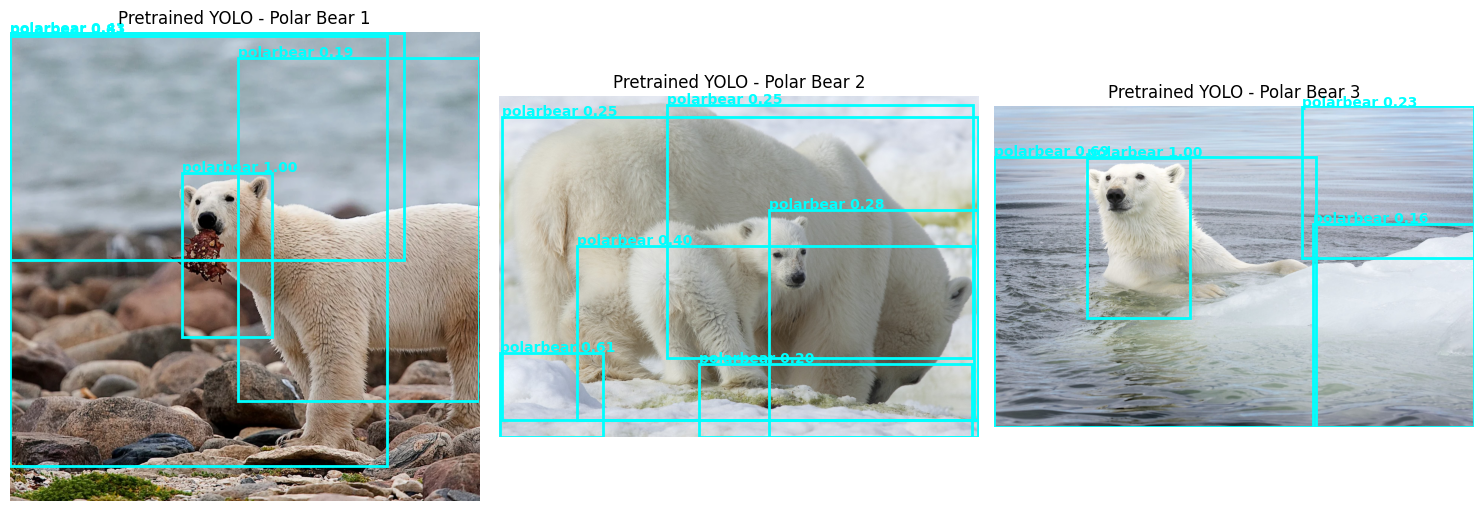

In [5]:
#Task 2 (YOLO): Training and testing pre-trained YOLO on my polar bears dataset

#We first load the yolov8n.pt (a PyTorch-based YOLO model pretrained on COCO),
#train it for 2 epochs on polar bear data, calculates mAP@50,
#and plots the predicted bounding boxes on polar bear validation set

!pip install ultralytics -q
from ultralytics import YOLO
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
import yaml
import os
import glob
import json
import shutil

# 1. Structure the dataset directory strictly to the standard YOLO format:
# /content/dataset/images and /content/dataset/labels
yolo_dataset_root = "/content/yolo_dataset"
images_dest_dir = os.path.join(yolo_dataset_root, "images")
labels_dest_dir = os.path.join(yolo_dataset_root, "labels")

os.makedirs(images_dest_dir, exist_ok=True)
os.makedirs(labels_dest_dir, exist_ok=True)

coco_json_path = "/content/labels-COCO-JSON.json"
source_images_dir = "/content/polarbearsdata/polarbearsdata"

# Load the COCO JSON file
with open(coco_json_path, 'r') as f:
    coco_data = json.load(f)

# Map image ID to filename and its dimensions
image_map = {}
for img in coco_data.get('images', []):
    image_map[img['id']] = {
        'file_name': img['file_name'],
        'width': img['width'],
        'height': img['height']
    }

# Group annotations by image_id
annotations_map = {}
for ann in coco_data.get('annotations', []):
    img_id = ann['image_id']
    if img_id not in annotations_map:
        annotations_map[img_id] = []
    annotations_map[img_id].append(ann)

# Copy images and convert bounding boxes to normalized YOLO format
for img_id, img_info in image_map.items():
    file_name = img_info['file_name']
    img_w = img_info['width']
    img_h = img_info['height']

    source_img_path = os.path.join(source_images_dir, file_name)
    if not os.path.exists(source_img_path):
         continue

    # Copy image to the strict images directory
    shutil.copy(source_img_path, os.path.join(images_dest_dir, file_name))

    # Save matching label file in the labels directory
    base_name = os.path.splitext(file_name)[0]
    label_path = os.path.join(labels_dest_dir, f"{base_name}.txt")

    yolo_lines = []
    anns = annotations_map.get(img_id, [])
    for ann in anns:
        bbox = ann.get('bbox', [])
        if len(bbox) == 4:
            x_min, y_min, w, h = bbox
            x_center = (x_min + w / 2.0) / img_w
            y_center = (y_min + h / 2.0) / img_h
            norm_w = w / img_w
            norm_h = h / img_h

            class_idx = 0
            yolo_lines.append(f"{class_idx} {x_center:.6f} {y_center:.6f} {norm_w:.6f} {norm_h:.6f}")

    with open(label_path, 'w') as lf:
        lf.write("\n".join(yolo_lines))

# 2. Write dataset.yaml configuration referring to the new clean structure
dataset_config = {
    'path': yolo_dataset_root,
    'train': 'images',
    'val': 'images',
    'names': {
        0: 'polarbear'
    }
}

yaml_path = os.path.join(yolo_dataset_root, 'dataset.yaml')
with open(yaml_path, 'w') as f:
    yaml.dump(dataset_config, f)

# 3. Load Pretrained YOLO and Train on Polar Bear Dataset
pretrained_yolo = YOLO("yolov8n.pt")
pretrained_yolo.train(
    data=yaml_path,
    epochs=2, # Keep low epochs for quick verification on CPU
    imgsz=416,
    batch=16,
    verbose=False,
    device='cpu'
)

# 4. Evaluate on Polar Bear Validation Split
yolo_metrics = pretrained_yolo.val(device='cpu')
print(f"Pretrained YOLO Polar Bear mAP@50: {yolo_metrics.box.map50:.3f}")

# 5. Visualize Polar Bear Predictions
val_imgs = sorted(glob.glob(os.path.join(images_dest_dir, "*")))[:3]
fig, axes = plt.subplots(1, min(3, len(val_imgs)), figsize=(15, 5) if len(val_imgs) > 1 else (5, 5))
if len(val_imgs) == 1:
    axes = [axes]

for i, img_path in enumerate(val_imgs):
    if os.path.isdir(img_path):
        continue
    pil_img = Image.open(img_path).convert("RGB")
    res = pretrained_yolo.predict(img_path, conf=0.15, verbose=False, device='cpu')[0]
    axes[i].imshow(pil_img)
    axes[i].set_title(f"Pretrained YOLO - Polar Bear {i+1}")
    axes[i].axis("off")
    for box, score in zip(res.boxes.xyxy.cpu(), res.boxes.conf.cpu()):
        x1, y1, x2, y2 = box.tolist()
        rect = patches.Rectangle((x1, y1), x2 - x1, y2 - y1, linewidth=2, edgecolor="cyan", facecolor="none")
        axes[i].add_patch(rect)
        axes[i].text(x1, max(0, y1 - 5), f"polarbear {score:.2f}", color="cyan", fontweight="bold")

plt.tight_layout()
plt.show()

Downloading: "https://download.pytorch.org/models/ssd300_vgg16_coco-b556d3b4.pth" to /root/.cache/torch/hub/checkpoints/ssd300_vgg16_coco-b556d3b4.pth


100%|██████████| 136M/136M [00:01<00:00, 140MB/s]


Pretrained SSD Epoch 01/10 | Polar Bear Loss: 5.4278
Pretrained SSD Epoch 02/10 | Polar Bear Loss: 2.9561
Pretrained SSD Epoch 03/10 | Polar Bear Loss: 2.0554
Pretrained SSD Epoch 04/10 | Polar Bear Loss: 1.5006
Pretrained SSD Epoch 05/10 | Polar Bear Loss: 1.1321
Pretrained SSD Epoch 06/10 | Polar Bear Loss: 0.8899
Pretrained SSD Epoch 07/10 | Polar Bear Loss: 0.7249
Pretrained SSD Epoch 08/10 | Polar Bear Loss: 0.5927
Pretrained SSD Epoch 09/10 | Polar Bear Loss: 0.5010
Pretrained SSD Epoch 10/10 | Polar Bear Loss: 0.4456


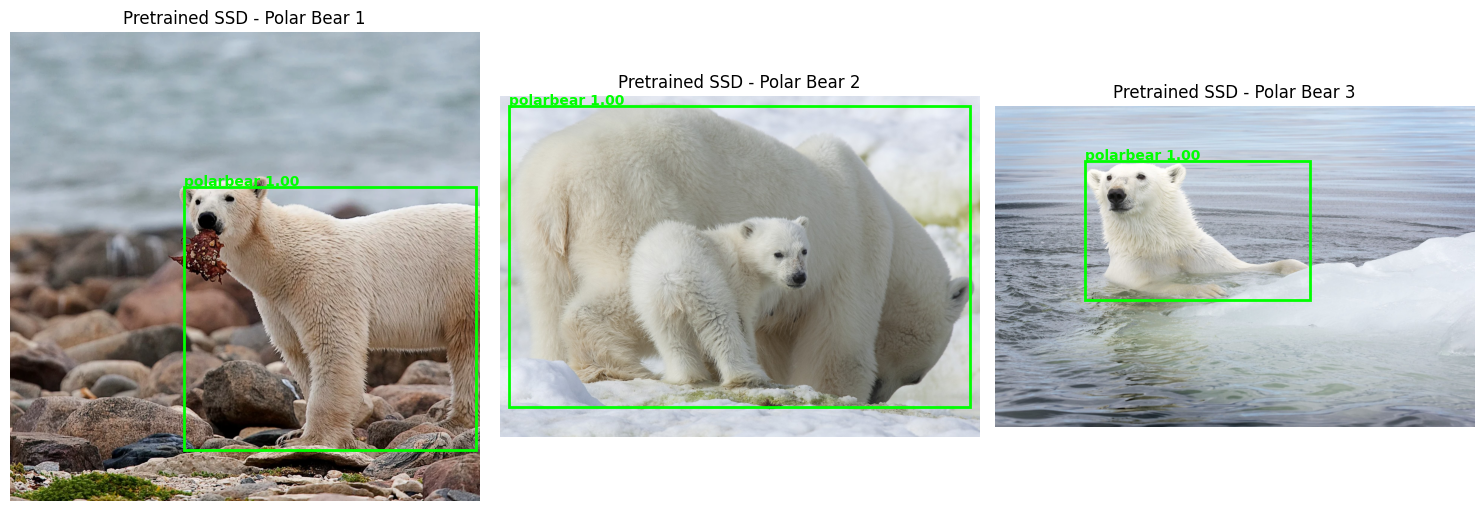

In [6]:
#Task 2 (Part 2): Training & testing pre-trained SSD on Polar Bear Data

#We load the ssd300_vgg16 from torchvision, replace its classification head
#for 2 classes (0 = background, 1 = polarbear), train it on polar bear
#training split for 10 epochs, and plot the predicted bounding boxes
#on the exact same polar bear test images.

import torchvision
from torchvision.models.detection.ssd import SSDClassificationHead
from torchvision import transforms
import glob
import os
import torch
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches

#Loading Pretrained SSD300-VGG16 and adapt head for 2 classes
 #(Background + Polar Bear)
pretrained_ssd = torchvision.models.detection.ssd300_vgg16(weights="DEFAULT")
in_channels = [512, 1024, 512, 256, 256, 256]
num_anchors = pretrained_ssd.anchor_generator.num_anchors_per_location()
pretrained_ssd.head.classification_head = SSDClassificationHead(in_channels, num_anchors, num_classes=2)
pretrained_ssd.to(device)

#Polar Bear Dataset Loader (reading images + YOLO box labels)
class PolarBearSSDDataset(torch.utils.data.Dataset):
    def __init__(self, dataset_root):
        # Point to the actual clean yolo_dataset directory created in Task 2 (YOLO)
        self.img_paths = sorted(glob.glob(os.path.join(dataset_root, "images", "*")))
        self.dataset_root = dataset_root

    def __len__(self):
        return len(self.img_paths)

    def __getitem__(self, idx):
        img_path = self.img_paths[idx]
        img = Image.open(img_path).convert("RGB")
        w, h = img.size
        img_tensor = transforms.ToTensor()(img)

        base = os.path.splitext(os.path.basename(img_path))[0]
        lbl_path = os.path.join(self.dataset_root, "labels", f"{base}.txt")
        boxes = []
        if os.path.exists(lbl_path):
            with open(lbl_path) as f:
                for line in f:
                    parts = line.strip().split()
                    if len(parts) == 5:
                        _, xc, yc, bw, bh = map(float, parts)
                        xmin, ymin = max(0.0, (xc - bw / 2) * w), max(0.0, (yc - bh / 2) * h)
                        xmax, ymax = min(float(w), (xc + bw / 2) * w), min(float(h), (yc + bh / 2) * h)
                        if xmax > xmin and ymax > ymin:
                            boxes.append([xmin, ymin, xmax, ymax])

        # If no boxes are annotated on this image, we supply a dummy background box to avoid PyTorch errors
        if len(boxes) == 0:
            boxes = [[0.0, 0.0, 1.0, 1.0]]
            labels = torch.zeros((1,), dtype=torch.int64) # Class 0 is background
        else:
            labels = torch.ones((len(boxes),), dtype=torch.int64) # Class 1 is polarbear

        return img_tensor, {
            "boxes": torch.tensor(boxes, dtype=torch.float32),
            "labels": labels
        }

# Instantiate the loader on the actual dataset root path
train_loader = torch.utils.data.DataLoader(
    PolarBearSSDDataset("/content/yolo_dataset"), batch_size=8, shuffle=True, collate_fn=lambda b: tuple(zip(*b))
)

# 3. Train Pretrained SSD on Polar Bear Dataset
optimizer = torch.optim.AdamW(pretrained_ssd.parameters(), lr=1e-4, weight_decay=1e-4)
for epoch in range(10):
    pretrained_ssd.train()
    total_loss = 0.0
    for imgs, targets in train_loader:
        imgs = [im.to(device) for im in imgs]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]
        loss_dict = pretrained_ssd(imgs, targets)
        loss = sum(l for l in loss_dict.values())
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    print(f"Pretrained SSD Epoch {epoch+1:02d}/10 | Polar Bear Loss: {total_loss/len(train_loader):.4f}")

# 4. Test & Visualize Pretrained SSD on Polar Bear Validation Images
pretrained_ssd.eval()
fig, axes = plt.subplots(1, min(3, len(val_imgs)), figsize=(15, 5) if len(val_imgs) > 1 else (5, 5))
if len(val_imgs) == 1:
    axes = [axes]

for i, img_path in enumerate(val_imgs):
    if os.path.isdir(img_path):
        continue
    pil_img = Image.open(img_path).convert("RGB")
    img_t = transforms.ToTensor()(pil_img).to(device)
    with torch.no_grad():
        out = pretrained_ssd([img_t])[0]
    axes[i].imshow(pil_img)
    axes[i].set_title(f"Pretrained SSD - Polar Bear {i+1}")
    axes[i].axis("off")
    for box, score in zip(out["boxes"].cpu(), out["scores"].cpu()):
        if score > 0.4:
            x1, y1, x2, y2 = box.tolist()
            rect = patches.Rectangle((x1, y1), x2 - x1, y2 - y1, linewidth=2, edgecolor="lime", facecolor="none")
            axes[i].add_patch(rect)
            axes[i].text(x1, max(0, y1 - 5), f"polarbear {score:.2f}", color="lime", fontweight="bold")

plt.tight_layout()
plt.show()

Pre-trained SSD performs better